In [1]:
# conda env 'misr'

import MisrToolkit as mtk
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

In [2]:
def nearest_sample(lat, lon, path, resolution):
    region = mtk.MtkRegion(lat,lon, 1, 1, "km")
    lats, lons = region.snap_to_grid(path, resolution).create_latlon()
    lats = lats.ravel()
    lons = lons.ravel()
    lat_diff = lats - lat
    lon_diff = lons - lon
    D = (lat_diff**2 + lon_diff**2)**0.5
    return lats[np.argmin(D)], lons[np.argmin(D)]

In [3]:
region_title = 'CAMP2Ex_RF17_Pris'
out_file = '../intermediate_data/CTH_flat_top.nc'

database = '../../data/MISR'
path = 117
orbit = 105254
cameras = ['DF', 'CF', 'BF', 'AF', 'AN', 'AA', 'BA', 'CA', 'DA']
lat, lon = nearest_sample(18.8549, 120.0052, path, 17600)

In [4]:
tc_cloud_general = '{}/MISR_AM1_TC_CLOUD_P{:d}_O{:d}_F01_0001.hdf'
# region = mtk.MtkRegion(path, 74, 76) # RF17
region = mtk.MtkRegion(lat, lon, 8.8*3, 8.8*3, "km")
lat1100, lon1100 = region.snap_to_grid(path, 1100).create_latlon()
lat17600, lon17600 = region.snap_to_grid(path, 17600).create_latlon()

In [5]:
grp_general = '{}/MISR_AM1_GRP_ELLIPSOID_GM_P{:d}_O{:d}_{}_F03_0024.hdf'
nadir_file = grp_general.format(database, path, orbit, 'AN')
lat275, lon275 = region.snap_to_grid(path, 275).create_latlon()
brf = mtk.MtkFile(nadir_file).grid('RedBand').field('Red Brf').read(region).data()

In [6]:
tc_cloud_file = tc_cloud_general.format(database, path, orbit)
tc_cloud_grid = mtk.MtkFile(tc_cloud_file).grid('Stereo_1.1_km')
CTH = tc_cloud_grid.field('CloudTopHeight').read(region).data().astype(np.float32)
CTH[CTH == -9999] = np.nan
CM = tc_cloud_grid.field('StereoDerivedCloudMask').read(region).data().astype(np.float32)
CM[CM == 0] = np.nan
SQUI = tc_cloud_grid.field('StereoQualityIndicator').read(region).data().astype(np.float32)
SQUI[SQUI == -128] = np.nan

In [7]:
cloud_data = xr.Dataset(
    data_vars = {
        'cth': (['y1100', 'x1100'], CTH),
        'cm': (['y1100', 'x1100'], CM),
        'squi': (['y1100', 'x1100'], SQUI),
        'lat1100': (['y1100', 'x1100'], lat1100),
        'lon1100': (['y1100', 'x1100'], lon1100),
        'center_lat': region.center[0],
        'center_lon': region.center[1]
    },
    attrs = {
        'orbit': orbit,
        'path': path,
        'blocks': region.block_range(path),
    }
)
cloud_data['cth'] = (['y1100', 'x1100'], 1400 * np.ones(CTH.shape)) ## Force into a slab cloud
cloud_data['cth'].attrs['units'] = 'm'
cloud_data['cth'].attrs['long_name'] = 'Cloud Top Height'
cloud_data['cm'].attrs['long_name'] = 'Cloud Mask'
cloud_data['squi'].attrs['long_name'] = 'Stereo Quality Indicator'
cloud_data.to_netcdf(out_file)

In [8]:
cloud_data

<xarray.Dataset>
Dimensions:     (x1100: 48, y1100: 48)
Dimensions without coordinates: x1100, y1100
Data variables:
    cth         (y1100, x1100) float64 1.4e+03 1.4e+03 ... 1.4e+03 1.4e+03
    cm          (y1100, x1100) float32 3.0 3.0 2.0 2.0 3.0 ... nan nan 1.0 3.0
    squi        (y1100, x1100) float32 45.0 41.0 77.0 88.0 ... nan nan 86.0 78.0
    lat1100     (y1100, x1100) float64 19.17 19.17 19.17 ... 18.67 18.67 18.67
    lon1100     (y1100, x1100) float64 119.8 119.8 119.8 ... 120.2 120.2 120.3
    center_lat  float64 18.92
    center_lon  float64 120.0
Attributes:
    orbit:    105254
    path:     117
    blocks:   (75, 76)

[299.5 309.5 319.5 329.5 339.5 349.5 359.5 369.5 379.5 389.5 399.5 409.5
 419.5 429.5 439.5 449.5 459.5 469.5 479.5 489.5 499.5 509.5 519.5 529.5
 539.5 549.5 559.5 569.5 579.5 589.5 599.5]


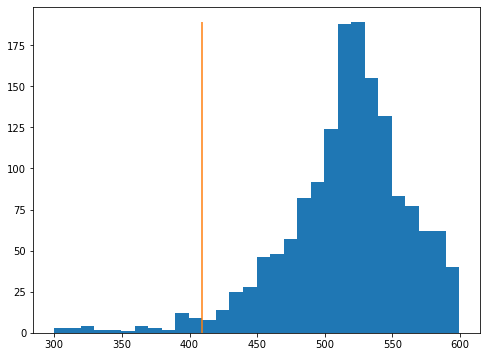

In [9]:
f, ax = plt.subplots(1, 1, figsize=(8,6))
bins = np.concatenate((np.arange(-311, 0, 10)+0.5, np.arange(0, 1400, 100)+0.5))
bins = np.arange(299, 601, 10) + 0.5
h = ax.hist(np.ravel(CTH), bins=bins)
ax.vlines(409.5, 0, np.max(h[0]), colors='tab:orange')
print(h[1])

In [ ]:
f, ax = plt.subplots(1, 1, figsize=(15,10))
ax.contourf(lon275, lat275, brf, cmap='gray', levels=100, vmin=0, vmax=None)
levels = np.concatenate((np.array([-400, 0]), np.arange(360, 1010, 100)))
nanCTH = CTH.copy()
nanCTH[CTH < 360] = np.nan
c = ax.contourf(lon1100, lat1100, CTH, alpha=0.4, vmin=360, vmax=1009, levels=None)
ax.scatter(np.ravel(lon17600), np.ravel(lat17600), c='tab:orange')
plt.colorbar(c, label='Cloud Top Height (m)')

In [ ]:
f, ax = plt.subplots(1, 1, figsize=(15,10))
ax.contourf(lon275, lat275, brf, cmap='gray', levels=100)
c = ax.contourf(lon1100, lat1100, SQUI, alpha=0.3)
plt.colorbar(c, label='Stereo Quality Indicator')

In [ ]:
f, ax = plt.subplots(1, 1, figsize=(15,10))
ax.contourf(lon275, lat275, brf, cmap='gray', levels=100)
# c = ax.contourf(lon1100, lat1100, CM, alpha=0.3, levels=np.array([0.5, 1.5, 2.5, 3.5, 4.5]))
c = ax.contourf(lon1100, lat1100, CM, alpha=0.3, levels=np.array([0.5, 2.5, 4.5]))
plt.colorbar(c, label='Cloud Mask')

In [ ]:
s = 130
f, ax = plt.subplots(1, 1, figsize=(8,6))
cond_nd = CM == 0
cond_hcc = CM == 1
cond_lcc = CM == 2
cond_lcs = CM == 3
cond_hcs = CM == 4
ax.scatter(lon1100[cond_nd], lat1100[cond_nd], c='r', marker='s', s=s, label='No Data')
ax.scatter(lon1100[cond_hcc], lat1100[cond_hcc], c='w', marker='s', s=s, label='High Confidence Cloud')
ax.scatter(lon1100[cond_lcc], lat1100[cond_lcc], c='gainsboro', marker='s', s=s, label='Low Confidence Cloud')
ax.scatter(lon1100[cond_lcs], lat1100[cond_lcs], c='dimgray', marker='s', s=s, label='Low Confidence Clear')
ax.scatter(lon1100[cond_hcs], lat1100[cond_hcs], c='k', marker='s', s=s, label='High Confidence Clear')
# ax.legend(loc='right')
